<a href="https://colab.research.google.com/github/FlavioRMiranda/EP-02---Assistencia-24h-Guincho/blob/main/EP_02_Assistencia_24h_Guincho.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1 - Instalação - Bibliotecas disponíveis

In [1]:

%pip -q install simpy numpy pandas matplotlib


2 - Parâmetros - Definição dos experimentos

In [2]:

import simpy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from collections import deque
from IPython.display import display

# Duração da chegada de novos pedidos: 24 horas
DURACAO_MIN = 24 * 60

# Parâmetros hipotéticos para o estudo
PROB_MECANICO = 0.70
PROB_SUCESSO_MECANICO = 0.80

# Tempos triangulares: mínimo, moda, máximo (minutos)
TEMPO_MECANICO = (20, 40, 75)
TEMPO_GUINCHO = (35, 70, 120)

# Espera acumulada acima deste limite é crítica
LIMITE_ESPERA_MIN = 60

# Configuração inicial das equipes
NUM_MECANICOS = 4
NUM_GUINCHOS = 3

# Taxas de chegada, em pedidos por hora
CENARIOS = {
    "Normal": 4,
    "Alta demanda": 5,
    "Extremo": 8
}

# Semente para permitir reprodução dos resultados
SEMENTE = 2026

print("Parâmetros carregados.")
print("Cenários:", CENARIOS)


Parâmetros carregados.
Cenários: {'Normal': 4, 'Alta demanda': 5, 'Extremo': 8}


3- Modelo SimPy - Simulador implementado

In [3]:

class SimulacaoAssistencia:

    def __init__(self, nome, taxa_hora, n_mecanicos,
                 n_guinchos, semente=2026):

        self.nome = nome
        self.taxa_hora = taxa_hora
        self.n_mecanicos = n_mecanicos
        self.n_guinchos = n_guinchos

        # Ambiente e gerador de números aleatórios
        self.env = simpy.Environment()
        self.rng = np.random.default_rng(semente)

        # Recursos compartilhados: atendimento FIFO
        self.mecanicos = simpy.Resource(
            self.env, capacity=n_mecanicos
        )
        self.guinchos = simpy.Resource(
            self.env, capacity=n_guinchos
        )

        # Identificadores individuais dos servidores
        self.livres = {
            "M": deque(
                f"M{i}" for i in range(1, n_mecanicos + 1)
            ),
            "G": deque(
                f"G{i}" for i in range(1, n_guinchos + 1)
            )
        }

        self.pedidos = []
        self.servicos = []
        self.estados = []
        self.ativos = 0

    def registrar_estado(self):
        """Registra o estado das filas e recursos."""
        self.estados.append({
            "tempo_h": self.env.now / 60,
            "fila_m": len(self.mecanicos.queue),
            "fila_g": len(self.guinchos.queue),
            "no_sistema": self.ativos,
            "ocup_m": self.mecanicos.count,
            "ocup_g": self.guinchos.count
        })

    def usar_recurso(self, pedido_id, tipo):
        """Solicita um servidor e executa o serviço."""

        if tipo == "M":
            recurso = self.mecanicos
            parametros = TEMPO_MECANICO
        else:
            recurso = self.guinchos
            parametros = TEMPO_GUINCHO

        entrada_fila = self.env.now

        # Solicita um mecânico ou guincho
        with recurso.request() as requisicao:

            self.registrar_estado()

            # Aguarda até haver servidor disponível
            yield requisicao

            espera = self.env.now - entrada_fila

            # Identifica qual servidor fará o serviço
            servidor = self.livres[tipo].popleft()

            self.registrar_estado()

            # Duração aleatória do serviço
            duracao = float(
                self.rng.triangular(*parametros)
            )

            inicio = self.env.now

            # Ocupa o recurso durante o atendimento
            yield self.env.timeout(duracao)

            fim = self.env.now

            self.servicos.append({
                "pedido_id": pedido_id,
                "tipo": tipo,
                "servidor": servidor,
                "inicio_min": inicio,
                "fim_min": fim,
                "duracao_min": duracao
            })

            # O servidor volta a ficar disponível
            self.livres[tipo].append(servidor)

        self.registrar_estado()

        return espera, duracao

    def atender_pedido(self, pedido):
        """Executa todas as etapas de um pedido."""

        pedido_id = pedido["id"]

        # Define o encaminhamento inicial
        if self.rng.random() < PROB_MECANICO:

            pedido["tipo_inicial"] = "Mecânico"

            espera, duracao = yield self.env.process(
                self.usar_recurso(pedido_id, "M")
            )

            pedido["espera_m_min"] = espera
            pedido["servico_m_min"] = duracao

            # Verifica se o mecânico resolveu o problema
            sucesso = (
                self.rng.random() < PROB_SUCESSO_MECANICO
            )

            if not sucesso:
                # Entra na fila de guinchos
                pedido["precisou_guincho"] = True

                espera, duracao = yield self.env.process(
                    self.usar_recurso(pedido_id, "G")
                )

                pedido["espera_g_min"] = espera
                pedido["servico_g_min"] = duracao

        else:
            # Pedido encaminhado diretamente ao guincho
            pedido["tipo_inicial"] = "Guincho"
            pedido["precisou_guincho"] = True

            espera, duracao = yield self.env.process(
                self.usar_recurso(pedido_id, "G")
            )

            pedido["espera_g_min"] = espera
            pedido["servico_g_min"] = duracao

        # Registra a conclusão do pedido
        pedido["saida_min"] = self.env.now

        pedido["espera_total_min"] = (
            pedido["espera_m_min"] +
            pedido["espera_g_min"]
        )

        pedido["tempo_total_min"] = (
            self.env.now - pedido["chegada_min"]
        )

        pedido["critico"] = (
            pedido["espera_total_min"] >
            LIMITE_ESPERA_MIN
        )

        self.ativos -= 1
        self.registrar_estado()

    def gerar_pedidos(self):
        """Gera pedidos por um período de 24 horas."""

        while True:

            # Intervalo exponencial entre chegadas
            intervalo = float(
                self.rng.exponential(
                    60 / self.taxa_hora
                )
            )

            proxima_chegada = self.env.now + intervalo

            # Encerra novas chegadas após 24 horas
            if proxima_chegada > DURACAO_MIN:

                yield self.env.timeout(
                    DURACAO_MIN - self.env.now
                )

                self.registrar_estado()
                return

            yield self.env.timeout(intervalo)

            pedido = {
                "id": len(self.pedidos) + 1,
                "chegada_min": self.env.now,
                "tipo_inicial": "",
                "precisou_guincho": False,
                "espera_m_min": 0.0,
                "espera_g_min": 0.0,
                "servico_m_min": 0.0,
                "servico_g_min": 0.0,
                "espera_total_min": 0.0,
                "tempo_total_min": 0.0,
                "saida_min": None,
                "critico": False
            }

            self.pedidos.append(pedido)
            self.ativos += 1

            self.registrar_estado()

            # Inicia o processo do pedido
            self.env.process(
                self.atender_pedido(pedido)
            )

    def executar(self):
        """Executa a simulação até concluir os pedidos."""

        self.registrar_estado()

        self.env.process(
            self.gerar_pedidos()
        )

        # Continua após 24h para concluir pendências
        self.env.run()

        self.registrar_estado()

        return self


4 - Execução - Tabela dos três cenários

In [4]:

def percentual_ocupacao(sim, tipo):
    """
    Calcula a utilização dos recursos dentro
    das primeiras 24 horas.
    """

    quantidade = (
        sim.n_mecanicos if tipo == "M"
        else sim.n_guinchos
    )

    trabalho = 0.0

    for servico in sim.servicos:

        if servico["tipo"] != tipo:
            continue

        inicio = servico["inicio_min"]
        fim = servico["fim_min"]

        # Considera só o trabalho dentro das 24h
        sobreposicao = max(
            0.0,
            min(fim, DURACAO_MIN) - max(inicio, 0.0)
        )

        trabalho += sobreposicao

    return 100 * trabalho / (quantidade * DURACAO_MIN)


def calcular_indicadores(sim):

    df = pd.DataFrame(sim.pedidos)

    if df.empty:
        return {
            "Cenário": sim.nome,
            "Pedidos": 0,
            "Espera média (min)": 0,
            "P95 espera (min)": 0,
            "Tempo total médio (min)": 0,
            "Críticos (%)": 0,
            "Pendentes às 24h": 0,
            "Uso mecânicos (%)": 0,
            "Uso guinchos (%)": 0,
            "Fim simulação (h)": 24
        }

    return {
        "Cenário": sim.nome,
        "Pedidos": len(df),

        "Espera média (min)": round(
            df["espera_total_min"].mean(), 2
        ),

        "P95 espera (min)": round(
            df["espera_total_min"].quantile(0.95), 2
        ),

        "Tempo total médio (min)": round(
            df["tempo_total_min"].mean(), 2
        ),

        "Críticos (%)": round(
            100 * df["critico"].mean(), 2
        ),

        "Pendentes às 24h": int(
            (df["saida_min"] > DURACAO_MIN).sum()
        ),

        "Uso mecânicos (%)": round(
            percentual_ocupacao(sim, "M"), 2
        ),

        "Uso guinchos (%)": round(
            percentual_ocupacao(sim, "G"), 2
        ),

        "Fim simulação (h)": round(
            sim.env.now / 60, 2
        )
    }


# Executar os três cenários
resultados = {}

for i, (nome, taxa) in enumerate(CENARIOS.items()):

    simulacao = SimulacaoAssistencia(
        nome=nome,
        taxa_hora=taxa,
        n_mecanicos=NUM_MECANICOS,
        n_guinchos=NUM_GUINCHOS,
        semente=SEMENTE + i
    )

    simulacao.executar()

    resultados[nome] = simulacao


# Montar tabela comparativa
tabela = pd.DataFrame([
    calcular_indicadores(sim)
    for sim in resultados.values()
])

display(tabela.round(2))


,Cenário,Pedidos,Espera média (min),P95 espera (min),Tempo total médio (min),Críticos (%),Pendentes às 24h,Uso mecânicos (%),Uso guinchos (%),Fim simulação (h)
0,Normal,85,6.86,44.97,69.74,2.35,4,51.35,49.48,25.65
1,Alta demanda,115,32.38,160.82,100.70,19.13,15,55.30,86.90,29.40
2,Extremo,170,116.48,493.59,181.68,54.12,37,80.37,96.32,34.30


5 - Visualização - 18 gráficos, seis por cenário

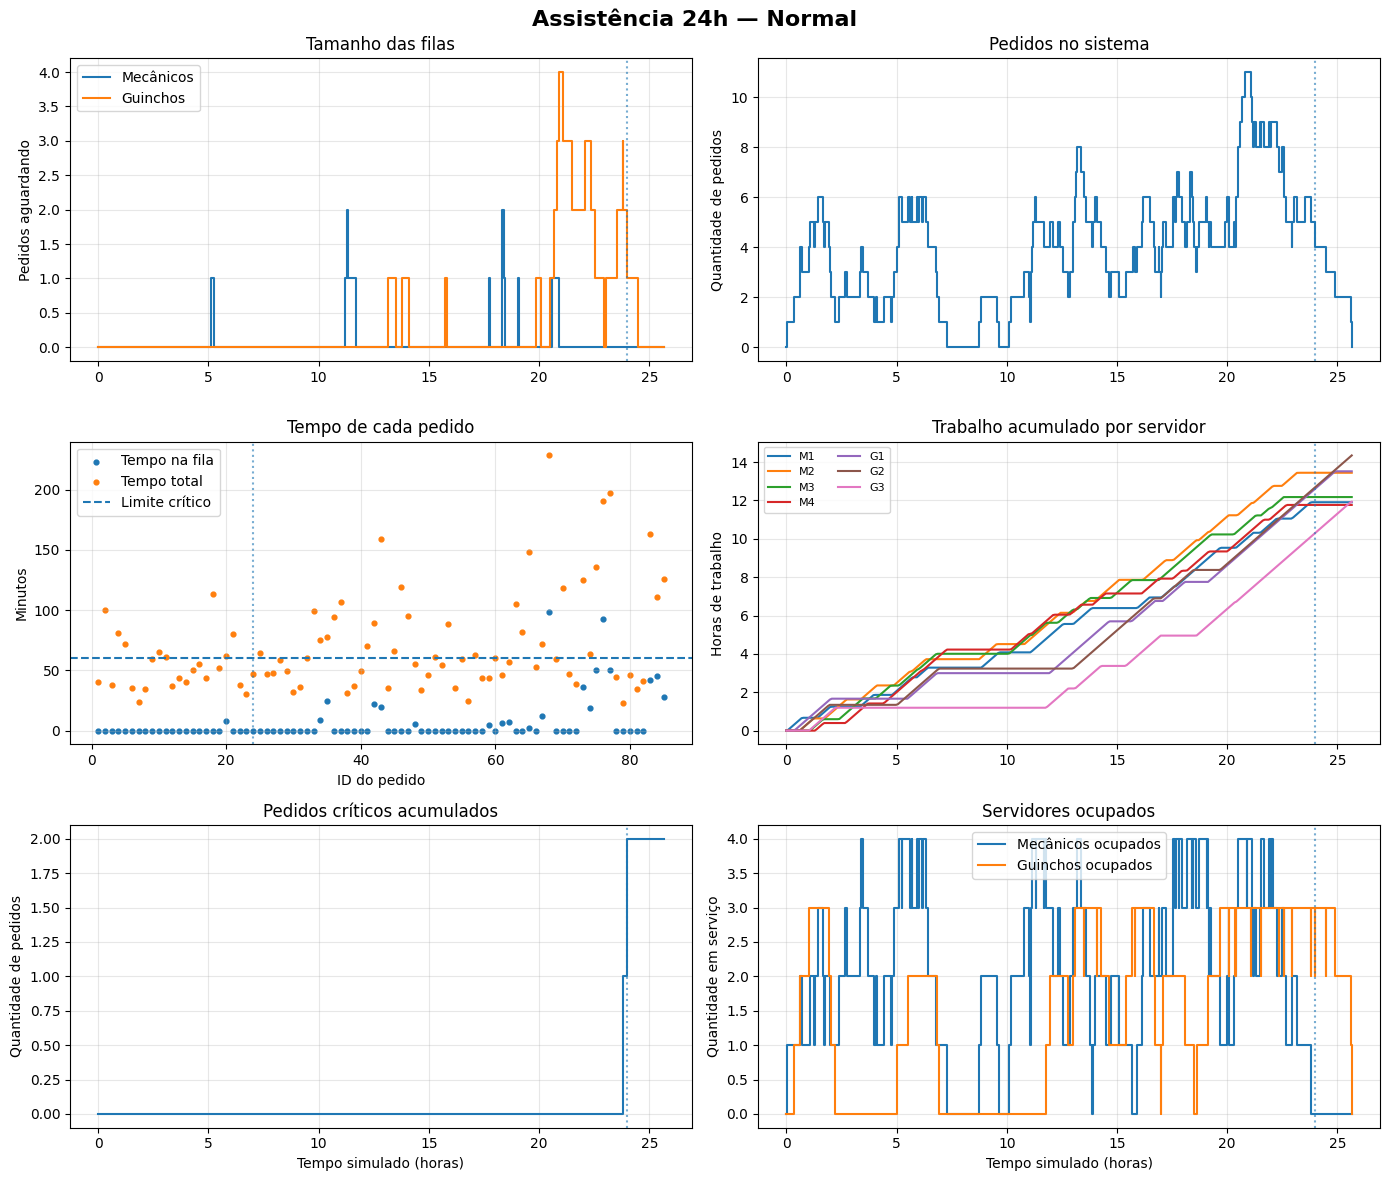

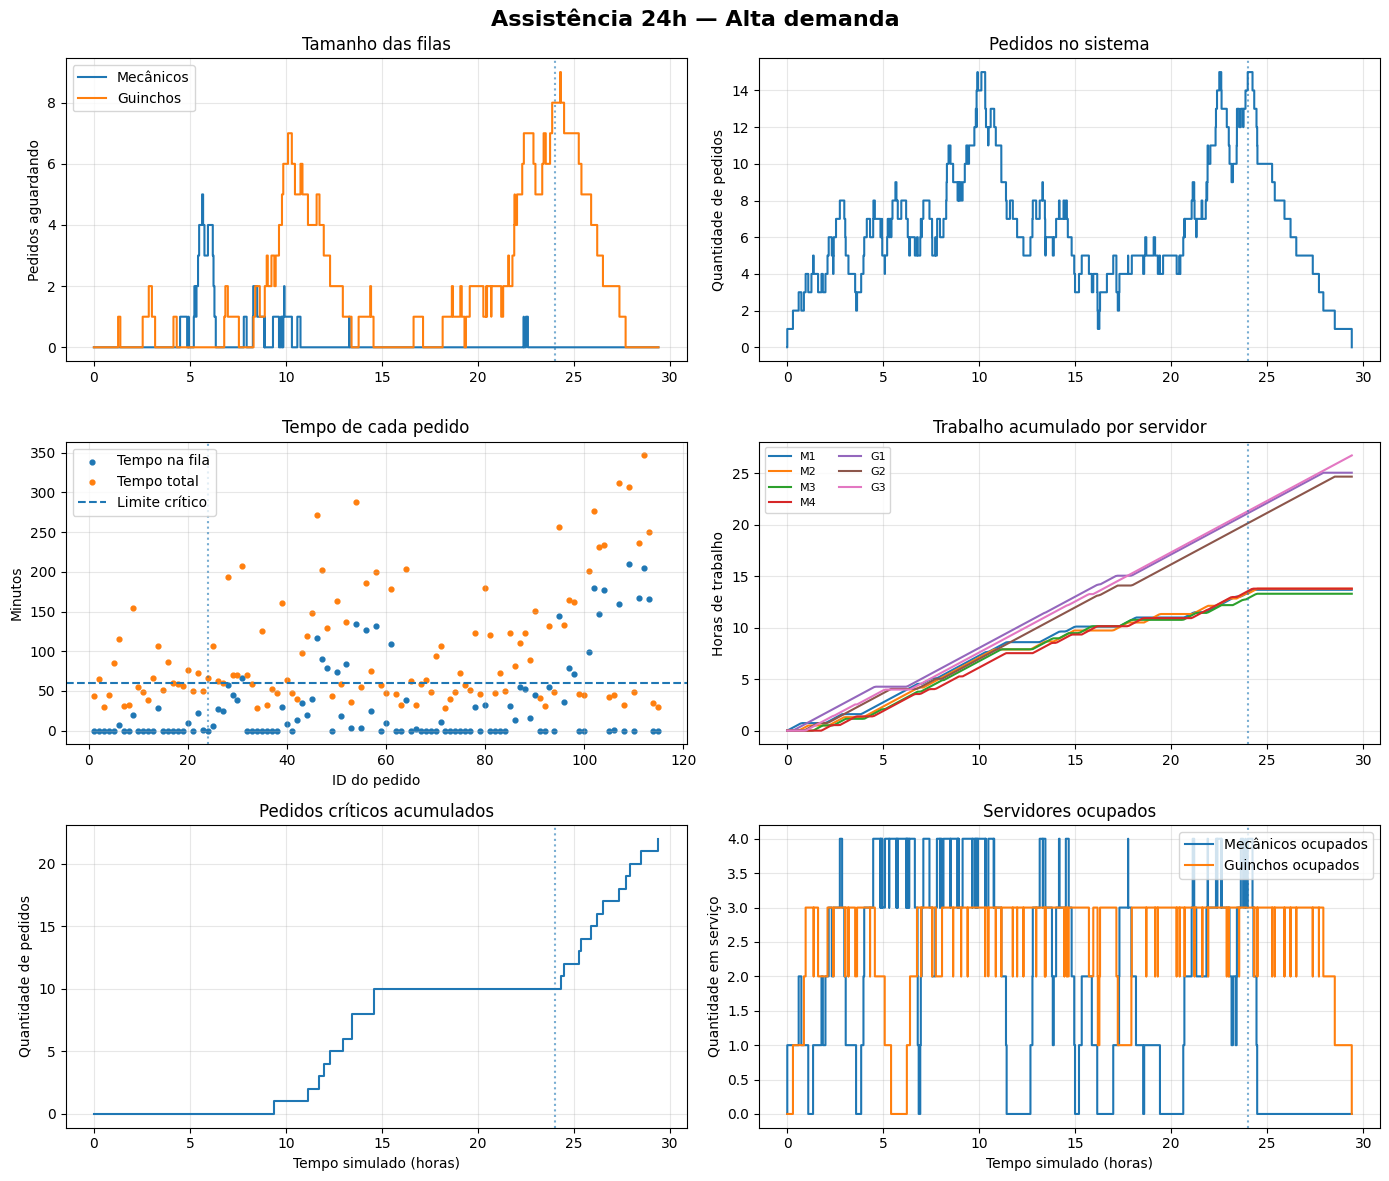

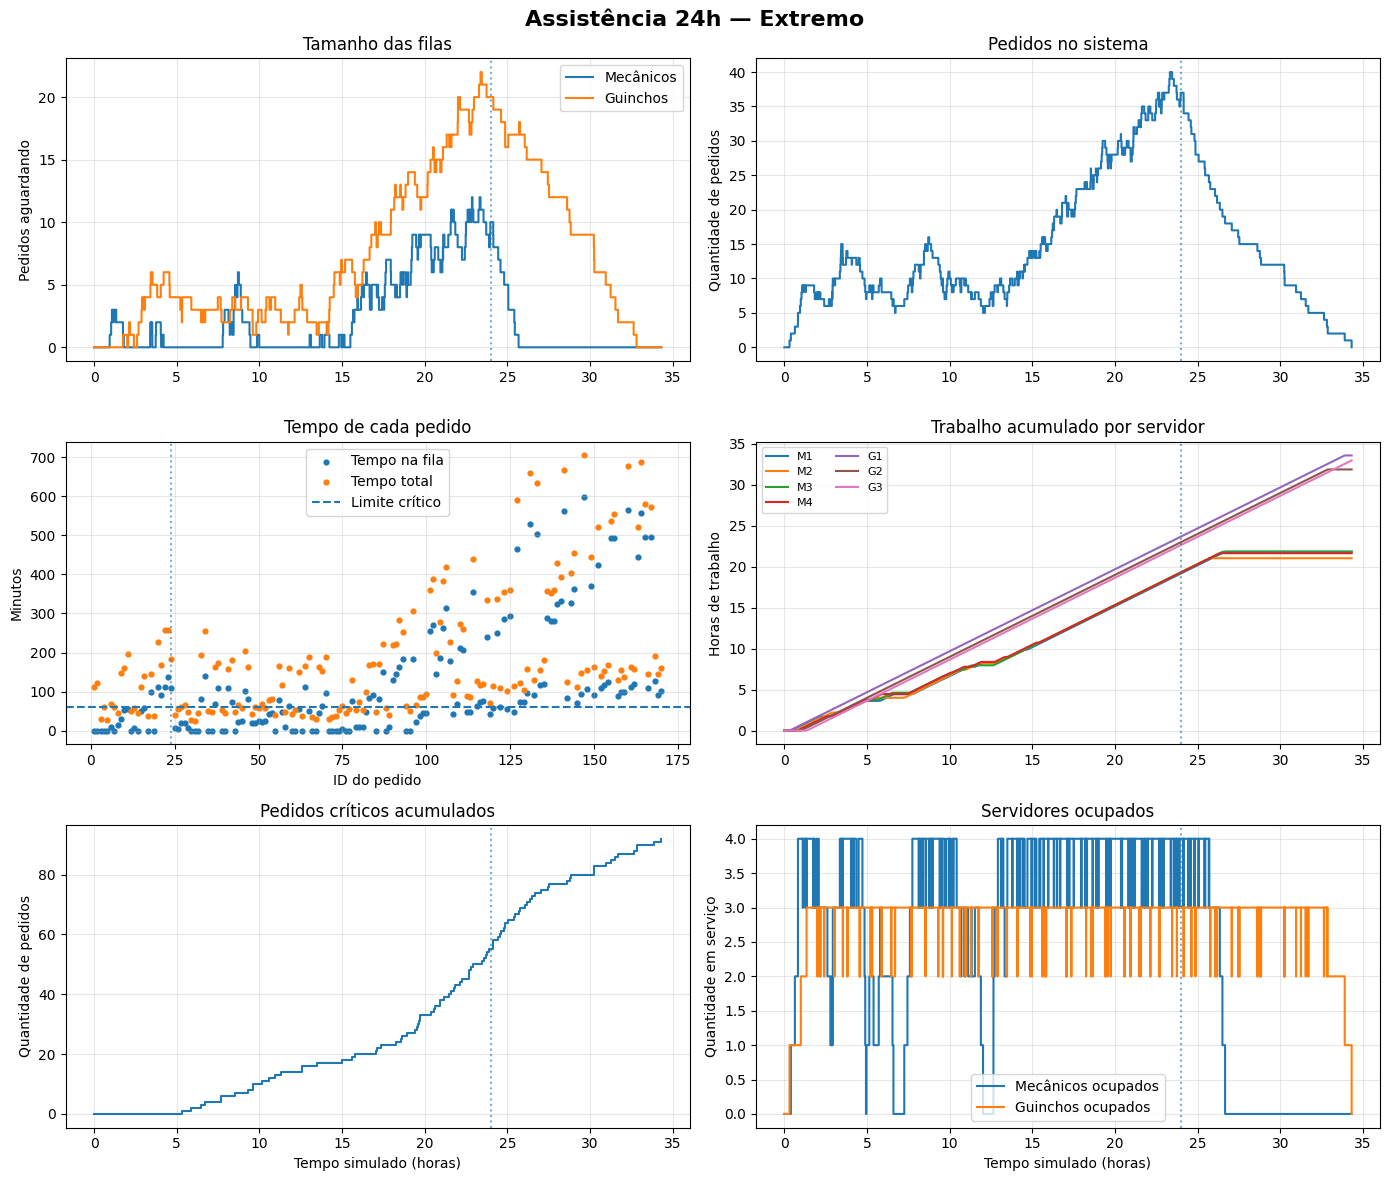

In [5]:

def plotar_cenario(sim):

    estados = pd.DataFrame(sim.estados)
    pedidos = pd.DataFrame(sim.pedidos)

    fig, axs = plt.subplots(
        3, 2, figsize=(14, 12)
    )

    fig.suptitle(
        f"Assistência 24h — {sim.nome}",
        fontsize=16,
        fontweight="bold"
    )

    # GRÁFICO 1 — Tamanho das filas
    ax = axs[0, 0]

    ax.step(
        estados["tempo_h"],
        estados["fila_m"],
        where="post",
        label="Mecânicos"
    )

    ax.step(
        estados["tempo_h"],
        estados["fila_g"],
        where="post",
        label="Guinchos"
    )

    ax.set_title("Tamanho das filas")
    ax.set_ylabel("Pedidos aguardando")
    ax.legend()
    ax.grid(alpha=0.3)

    # GRÁFICO 2 — Pedidos no sistema
    ax = axs[0, 1]

    ax.step(
        estados["tempo_h"],
        estados["no_sistema"],
        where="post"
    )

    ax.set_title("Pedidos no sistema")
    ax.set_ylabel("Quantidade de pedidos")
    ax.grid(alpha=0.3)

    # GRÁFICO 3 — Tempos individuais
    ax = axs[1, 0]

    ax.scatter(
        pedidos["id"],
        pedidos["espera_total_min"],
        s=12,
        label="Tempo na fila"
    )

    ax.scatter(
        pedidos["id"],
        pedidos["tempo_total_min"],
        s=12,
        label="Tempo total"
    )

    ax.axhline(
        LIMITE_ESPERA_MIN,
        linestyle="--",
        label="Limite crítico"
    )

    ax.set_title("Tempo de cada pedido")
    ax.set_xlabel("ID do pedido")
    ax.set_ylabel("Minutos")
    ax.legend()
    ax.grid(alpha=0.3)

    # GRÁFICO 4 — Trabalho acumulado por servidor
    ax = axs[1, 1]

    eixo_h = np.linspace(
        0, sim.env.now / 60, 300
    )

    for tipo, quantidade in [
        ("M", sim.n_mecanicos),
        ("G", sim.n_guinchos)
    ]:
        for i in range(1, quantidade + 1):

            servidor = f"{tipo}{i}"
            acumulado = np.zeros_like(eixo_h)

            for servico in sim.servicos:

                if servico["servidor"] != servidor:
                    continue

                inicio = servico["inicio_min"] / 60
                fim = servico["fim_min"] / 60

                acumulado += np.clip(
                    eixo_h - inicio,
                    0,
                    fim - inicio
                )

            ax.plot(
                eixo_h,
                acumulado,
                label=servidor
            )

    ax.set_title("Trabalho acumulado por servidor")
    ax.set_ylabel("Horas de trabalho")
    ax.legend(ncol=2, fontsize=8)
    ax.grid(alpha=0.3)

    # GRÁFICO 5 — Pedidos críticos acumulados
    ax = axs[2, 0]

    ordenados = pedidos.sort_values("saida_min")

    criticos = (
        ordenados["critico"]
        .astype(int)
        .cumsum()
    )

    ax.step(
        [0] + (ordenados["saida_min"] / 60).tolist(),
        [0] + criticos.tolist(),
        where="post"
    )

    ax.set_title("Pedidos críticos acumulados")
    ax.set_ylabel("Quantidade de pedidos")
    ax.grid(alpha=0.3)

    # GRÁFICO 6 — Servidores ocupados
    ax = axs[2, 1]

    ax.step(
        estados["tempo_h"],
        estados["ocup_m"],
        where="post",
        label="Mecânicos ocupados"
    )

    ax.step(
        estados["tempo_h"],
        estados["ocup_g"],
        where="post",
        label="Guinchos ocupados"
    )

    ax.set_title("Servidores ocupados")
    ax.set_ylabel("Quantidade em serviço")
    ax.legend()
    ax.grid(alpha=0.3)

    # Indica o final das 24h de chegadas
    for ax in axs.flat:
        ax.axvline(24, linestyle=":", alpha=0.6)

    for ax in axs[2, :]:
        ax.set_xlabel("Tempo simulado (horas)")

    plt.tight_layout()
    plt.show()


# Gerar gráficos dos três cenários
for nome, simulacao in resultados.items():
    plotar_cenario(simulacao)


6 - Dimensionamento - Comparação de equipes

In [6]:

# Estudo de dimensionamento para o cenário extremo
REPETICOES = 10
linhas = []

for nm in range(4, 8):
    for ng in range(3, 8):

        for repeticao in range(REPETICOES):

            sim = SimulacaoAssistencia(
                nome="Dimensionamento",
                taxa_hora=CENARIOS["Extremo"],
                n_mecanicos=nm,
                n_guinchos=ng,
                semente=10000 + repeticao
            )

            sim.executar()

            indicadores = calcular_indicadores(sim)

            linhas.append({
                "Mecânicos": nm,
                "Guinchos": ng,
                "Espera média (min)": indicadores[
                    "Espera média (min)"
                ],
                "Críticos (%)": indicadores[
                    "Críticos (%)"
                ],
                "Pendentes às 24h": indicadores[
                    "Pendentes às 24h"
                ]
            })


# Calcular médias das repetições
comparacao = (
    pd.DataFrame(linhas)
    .groupby(
        ["Mecânicos", "Guinchos"],
        as_index=False
    )
    .mean(numeric_only=True)
)

comparacao["Total recursos"] = (
    comparacao["Mecânicos"] +
    comparacao["Guinchos"]
)

# Critérios hipotéticos de qualidade
comparacao["Atende metas"] = (
    (comparacao["Espera média (min)"] <= 30) &
    (comparacao["Críticos (%)"] <= 10)
)

# Ordena as configurações pelo número de recursos
comparacao = comparacao.sort_values(
    ["Total recursos", "Espera média (min)"]
)

print("Comparação das configurações:")
display(comparacao.round(2))

# Seleciona a alternativa com menos recursos
viaveis = comparacao[
    comparacao["Atende metas"]
]

if not viaveis.empty:

    melhor = viaveis.iloc[0]

    print("\nMelhor configuração testada:")
    print("Mecânicos:", int(melhor["Mecânicos"]))
    print("Guinchos:", int(melhor["Guinchos"]))

    print(
        "Espera média:",
        round(melhor["Espera média (min)"], 2),
        "min"
    )

    print(
        "Pedidos críticos:",
        round(melhor["Críticos (%)"], 2),
        "%"
    )

else:
    print(
        "Nenhuma configuração testada atendeu "
        "às metas. Amplie o intervalo de equipes."
    )


Comparação das configurações:


,Mecânicos,Guinchos,Espera média (min),Críticos (%),Pendentes às 24h,Total recursos,Atende metas
0,4,3,199.64,63.51,45.8,7,False
1,4,4,103.85,58.00,27.0,8,False
5,5,3,137.77,39.55,33.6,8,False
2,4,5,69.39,43.69,23.7,9,False
6,5,4,76.79,36.12,25.4,9,False
10,6,3,148.64,38.25,34.3,9,False
7,5,5,34.08,22.88,15.1,10,False
11,6,4,49.77,26.41,20.4,10,False
3,4,6,77.16,47.19,23.1,10,False
15,7,3,161.36,38.70,35.4,10,False



Melhor configuração testada:
Mecânicos: 5
Guinchos: 6
Espera média: 10.71 min
Pedidos críticos: 1.67 %
